<a href="https://colab.research.google.com/github/caiohc28/Tech_Challenge/blob/main/Comportamento_e_Pagamentos_Olist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comportamento e Pagamentos | Olist

Objetivo: analisar o comportamento de compra do cliente

Perguntas que este notebook responde:

1 . Quais os meios de pagamentos mais utilizados?

2 . Qual a correlação entre o valor gasto e o número de parcelas

3 . Qual a recencia, frequencia e monetização por cliente único

4 . Qual a taxa de retenção e recompra por coorte (mês em que o cliente realizou a primeira compra)


Base de análise: pedidos entregues, com datas de aprovação e de entrega preenchidas.
Fonte: Brazilian E-Commerce Public Dataset by Olist (Kaggle).

## 1. Importação das bibliotecas


In [ ]:
# manipuluação dos dados
import pandas as pd
import numpy as np

# visualização dos dados
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

## 2. Carregamento dos dados

In [ ]:
df_olist = pd.read_csv('olist_customers_dataset.csv')

## 3. Criação dataset ordens e pagamentos


In [ ]:
df_orders = pd.read_csv('olist_orders_dataset.csv')
df_payments = pd.read_csv('olist_order_payments_dataset.csv')

## 4. Visualização das Estatísticas Descritivas por Meio de Pagamento e quantidade de trançãoes (count)



In [ ]:
# Agrupamento por tipo de pagamento e obtendo estatísticas descritivas para o valor e número de parcelas
estatisticas_pagamento = df_payments.groupby('payment_type')[['payment_value', 'payment_installments']].describe()
display(estatisticas_pagamento)

payment_value                                                  \
                     count        mean         std    min      25%     50%   
payment_type                                                                 
boleto             19784.0  145.034435  213.581061  11.62  55.5225   93.89   
credit_card        76795.0  163.319021  222.119311   0.01  62.2100  106.87   
debit_card          1529.0  142.570170  245.793401  13.38  51.1000   89.30   
not_defined            3.0    0.000000    0.000000   0.00   0.0000    0.00   
voucher             5775.0   65.703354  115.519185   0.00  18.0350   39.28   

                                 payment_installments                          \
                   75%       max                count      mean      std  min   
payment_type                                                                    
boleto        160.7625   7274.88              19784.0  1.000000  0.00000  1.0   
credit_card   181.2100  13664.08              76795.0  3.507155  2.85099  0.0   
debit_card    154.3200   4445.50               1529.0  1.000000  0.00000  1.0   
not_defined     0.0000      0.00                  3.0  1.000000  0.00000  1.0   
voucher        80.0000   3184.34               5775.0  1.000000  0.00000  1.0   

                                   
              25%  50%  75%   max  
payment_type                       
boleto        1.0  1.0  1.0   1.0  
credit_card   1.0  3.0  5.0  24.0  
debit_card    1.0  1.0  1.0   1.0  
not_defined   1.0  1.0  1.0   1.0  
voucher       1.0  1.0  1.0   1.0

Quantidade de Transações (count):

O cartão de crédito (credit_card) é o método mais utilizado, com mais de 76 mil transações. O boleto vem em segundo lugar, com cerca de 19,7 mil transações. Voucher e cartão de débito (debit_card) aparecem na sequência.

## 1. Quais os Meios de Pagamento Mais Utilizados?

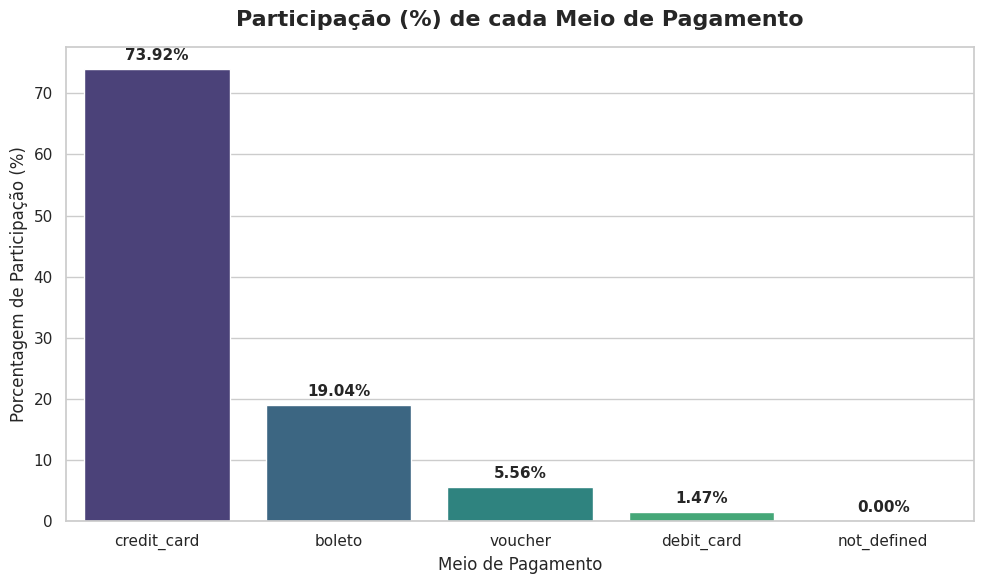

In [ ]:
# Grafico de barras em porcentagem

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# Calculando as porcentagens
payment_percentage = (df_payments['payment_type'].value_counts(normalize=True) * 100)

sns.barplot(x=payment_percentage.index, y=payment_percentage.values, ax=ax, palette='viridis', hue=payment_percentage.index, legend=False)
ax.set_title('Participação (%) de cada Meio de Pagamento', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Meio de Pagamento', fontsize=12)
ax.set_ylabel('Porcentagem de Participação (%)', fontsize=12)

# Adicionando os valores percentuais formatados em cima de cada barra
for i, v in enumerate(payment_percentage.values):
    ax.text(i, v + 1, f'{v:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

A distribuição de meios de pagamento comporta-se com dominância expressiva do Cartão de Crédito (73.92%), seguido pelo Boleto (19.04%), Voucher (5.56%) e Cartão de Débito (1.47%).

Análise do valor gasto e o número de parcelas



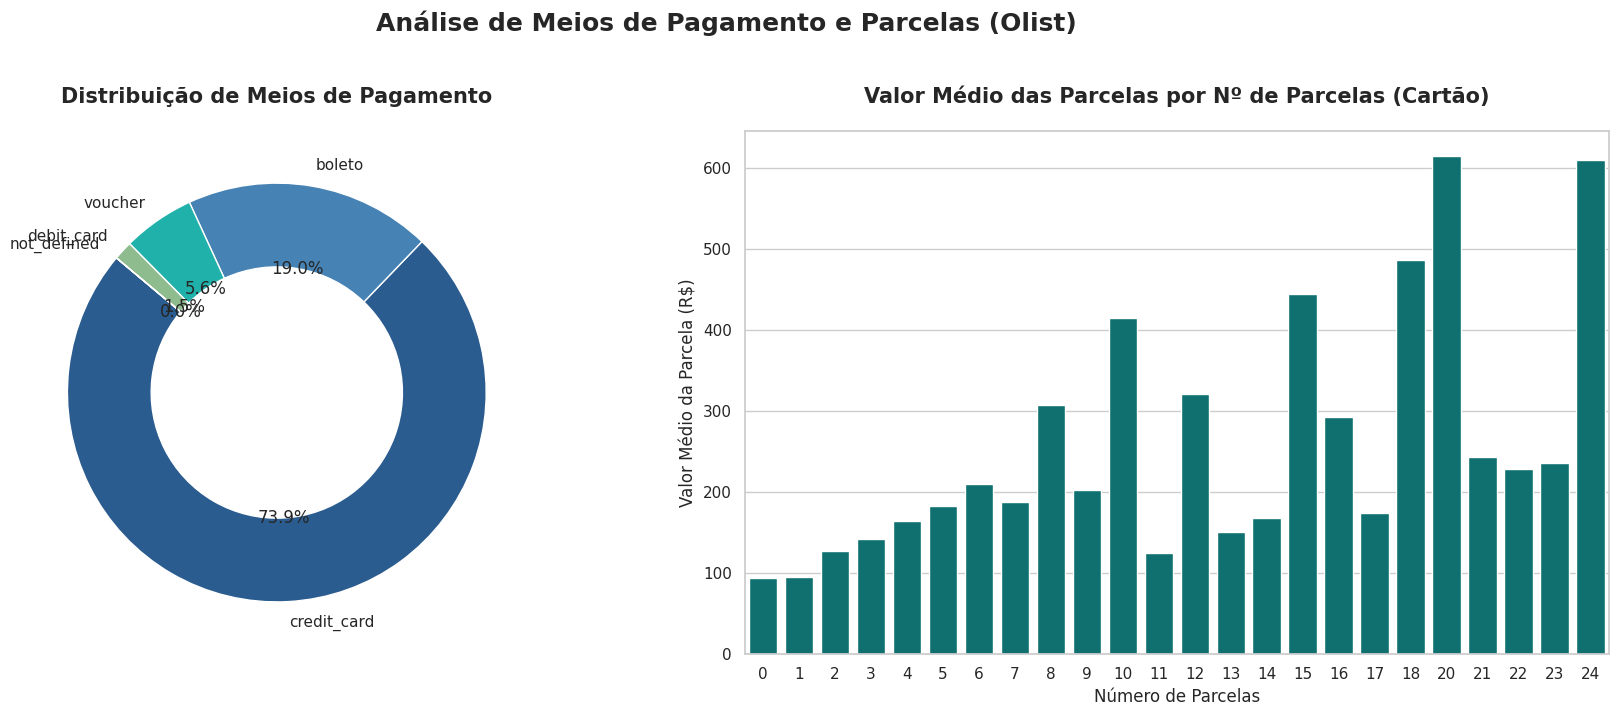

In [ ]:
# Criação um DataFrame a partir da contagem de valores para garantir o acesso correto às colunas
payment_counts = df_payments['payment_type'].value_counts().reset_index()
payment_counts.columns = ['payment_type', 'count']

# Preparação dos dados para o gráfico de barras (Valor Médio das Parcelas por Nº de Parcelas)
# Filtrar apenas as transações de cartão de crédito que possuem parcelas maiores que zero
df_credit = df_payments[df_payments['payment_type'] == 'credit_card']
installments_value = df_credit.groupby('payment_installments')['payment_value'].mean().reset_index()

# Estilo visual geral
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Gráfico de Pizza (Distribuição dos Meios de Pagamento) ---
cores = ['#2b5c8f', '#4682b4', '#20b2aa', '#8fbc8f', '#d3d3d3']
axes[0].pie(
    payment_counts['count'],
    labels=payment_counts['payment_type'],
    autopct='%1.1f%%',
    startangle=140,
    colors=cores,
    wedgeprops=dict(width=0.4, edgecolor='w') # Formato de rosca elegante
)
axes[0].set_title('Distribuição de Meios de Pagamento', fontsize=15, fontweight='bold', pad=20)

# Gráfico de Barras (Valor Médio das Parcelas) ---
sns.barplot(
    data=installments_value,
    x='payment_installments',
    y='payment_value',
    ax=axes[1],
    color='teal'
)
axes[1].set_title('Valor Médio das Parcelas por Nº de Parcelas (Cartão)', fontsize=15, fontweight='bold', pad=20)
axes[1].set_xlabel('Número de Parcelas', fontsize=12)
axes[1].set_ylabel('Valor Médio da Parcela (R$)', fontsize=12)

# Título unificado e ajustar espaçamentos
plt.suptitle('Análise de Meios de Pagamento e Parcelas (Olist)', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

O Ticket Médio por Número de Parcelas flutua à medida que o número de parcelas aumenta, evidenciando picos característicos de compras de alto valor parceladas em 10, 15, 20 ou 24 vezes no cartão de crédito.

## 2. Qual a correlação entre o valor gasto e o número de parcelas?


In [ ]:
# Cálculo da correlação de Pearson e Spearman
corr_pearson = df_payments['payment_value'].corr(df_payments['payment_installments'], method='pearson')
corr_spearman = df_payments['payment_value'].corr(df_payments['payment_installments'], method='spearman')

print(f"Coeficiente de Correlação de Pearson: {corr_pearson:.4f}")
print(f"Coeficiente de Correlação de Spearman: {corr_spearman:.4f}")

Coeficiente de Correlação de Pearson: 0.3308
Coeficiente de Correlação de Spearman: 0.4111


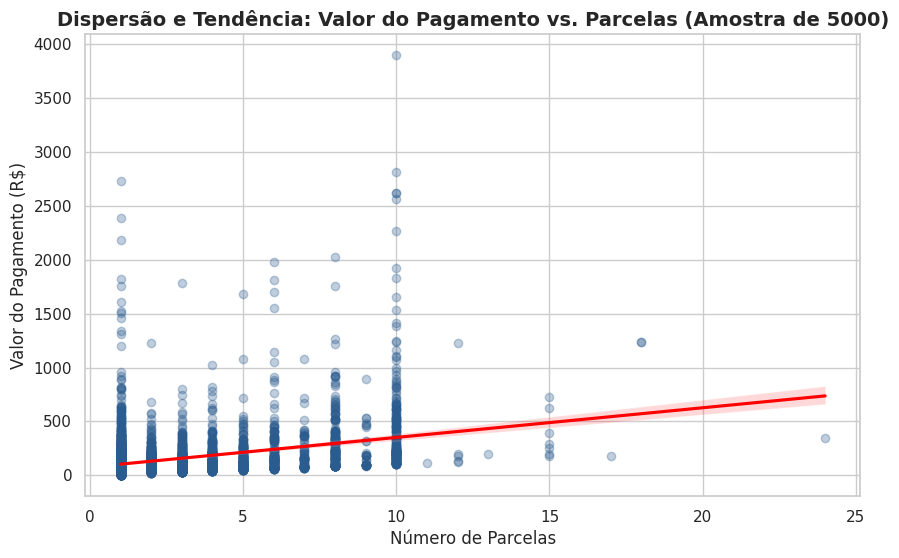

In [ ]:
# Gráfico de dispersão com uma amostra de 5000
df_sample = df_payments.sample(n=5000, random_state=42) if len(df_payments) > 5000 else df_payments

plt.figure(figsize=(10, 6))
sns.regplot(data=df_sample, x='payment_installments', y='payment_value',
            scatter_kws={'alpha':0.3, 'color': '#2b5c8f'}, line_kws={'color': 'red'})

plt.title('Dispersão e Tendência: Valor do Pagamento vs. Parcelas (Amostra de 5000)', fontsize=14, fontweight='bold')
plt.xlabel('Número de Parcelas', fontsize=12)
plt.ylabel('Valor do Pagamento (R$)', fontsize=12)
plt.show()

O cálculo da correlação de Pearson foi de 0.33 e a Correlação de Spearman foi de 0,41. No gráfico de dispersão com a linha de tendência (vermelha), percebe-se claramente que compras de maior valor (especialmente acima de R$ 1.000) tendem a se concentrar em números maiores de parcelas (como 10 parcelas).
Compras de menor valor ocorrem em qualquer quantidade de parcelas, mas compras de maior valor quase nunca são feitas em poucas parcelas.
Portanto, sim, há uma correlação positiva moderada: quanto maior o valor da compra, mais os clientes tendem a parcelar.

## 3. Qual a Recência, frequência, monetização (RFM) por customer unique





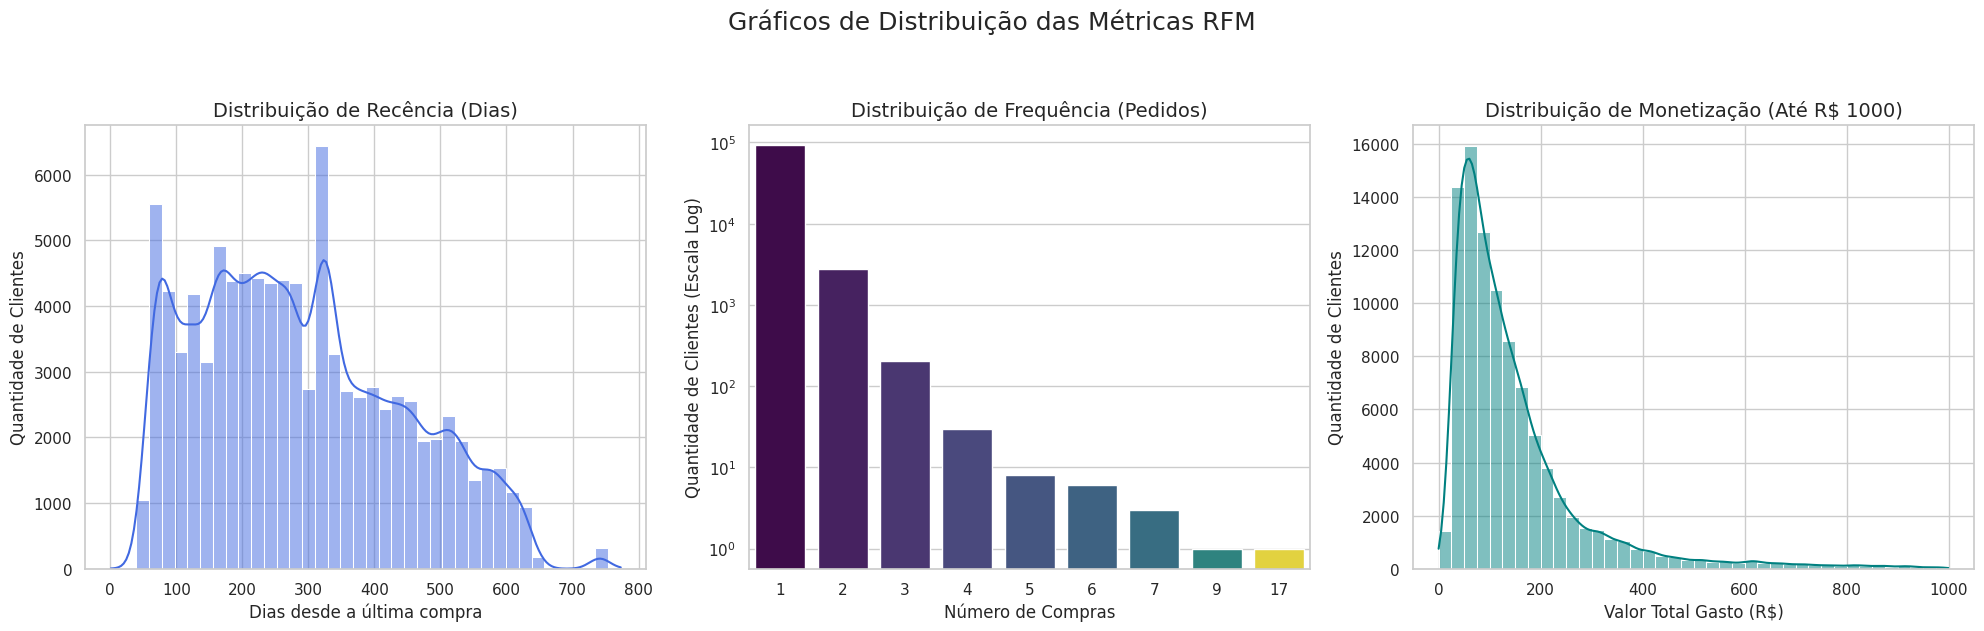

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo visual dos gráficos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Distribuição de Recência
sns.histplot(df_rfm['Recencia'], bins=40, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Distribuição de Recência (Dias)', fontsize=14)
axes[0].set_xlabel('Dias desde a última compra')
axes[0].set_ylabel('Quantidade de Clientes')

# 2. Distribuição de Frequência
# Como a grande maioria possui frequência = 1, limitamos e usamos escala logarítmica para evidenciar a recorrência
sns.countplot(data=df_rfm, x='Frequencia', ax=axes[1], palette='viridis', hue='Frequencia', legend=False)
axes[1].set_title('Distribuição de Frequência (Pedidos)', fontsize=14)
axes[1].set_xlabel('Número de Compras')
axes[1].set_ylabel('Quantidade de Clientes (Escala Log)')
axes[1].set_yscale('log')

# 3. Distribuição de Monetização
# Limite no eixo X (até R$ 1000) para evitar distorções causadas por outliers de valores muito elevados
monetizacao_filtrada = df_rfm[df_rfm['Monetizacao'] <= 1000]
sns.histplot(monetizacao_filtrada['Monetizacao'], bins=40, kde=True, ax=axes[2], color='teal')
axes[2].set_title('Distribuição de Monetização (Até R$ 1000)', fontsize=14)
axes[2].set_xlabel('Valor Total Gasto (R$)')
axes[2].set_ylabel('Quantidade de Clientes')

plt.suptitle('Gráficos de Distribuição das Métricas RFM', fontsize=18, y=1.05)
plt.tight_layout()
plt.show()

A Distribuição de Recência (Dias desde a última compra): o gráfico mostra que os clientes estão amplamente distribuídos em uma faixa que vai de 0 a mais de 700 dias. É possível observar picos expressivos de atividade ao redor de 80 a 100 dias e um pico ainda maior próximo dos 320 dias. Isso sinaliza campanhas ou períodos sazonais de grande volume de vendas no histórico do Olist. Como a barra mais alta se concentra próxima aos 320 dias, uma parte muito significativa da base de clientes não realiza compras há quase um ano, exigindo estratégias urgentes de reengajamento.

Distribuição de Frequência (Quantidade de Pedidos) Devido à escala logarítmica necessária para visualização, fica claro que a maioria dos clientes (mais de 90.000) possui frequência igual a 1, ou seja há uma alta concentração de compra única. O número de clientes que efetuam 2 ou mais compras cai drasticamente (menos de 3.000 clientes realizaram 2 compras). Clientes com frequências atípicas (como 5, 9 ou até 17 compras) são raríssimas exceções (outliers).

Distribuição de Monetização - Valor Total Gasto até 1000,00 reais. Assimetria Positiva Acentuada (Cauda Longa): o gráfico revela que a grande massa de transações ocorre em valores baixos. O pico de frequência de clientes está concentrado entre 40,00 e 150,00 reais À medida que o valor total gasto se aproxima de 400,00 reais, a quantidade de clientes cai de forma muito acentuada, tornando o grupo de clientes que gastam acima de R$ 600,00 bastante seleto e de altíssimo valor (VIPs) para focar em estratégias de relacionamento.

## 4. Qual a taxa de retenção e recompra por coorte (mês em que o cliente realizou a primeira compra)


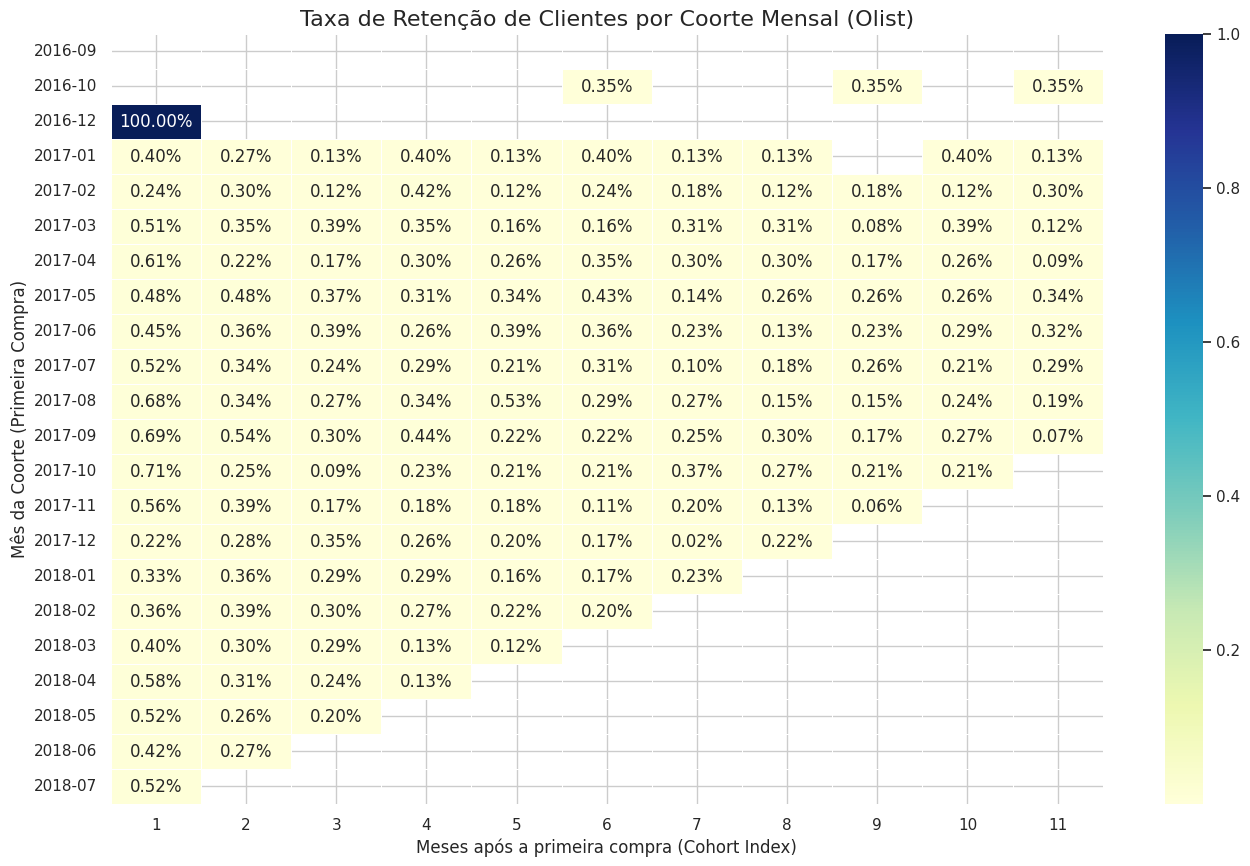

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Unir df_orders com df_olist para ter o customer_unique_id associado às datas de compra
df_cohort = df_orders.merge(df_olist, on='customer_id', how='inner')
df_cohort['order_purchase_timestamp'] = pd.to_datetime(df_cohort['order_purchase_timestamp'])

# Filtrar apenas pedidos entregues ou faturados para garantir compras válidas
df_cohort = df_cohort[df_cohort['order_status'].isin(['delivered', 'shipped', 'invoiced'])]

# Coluna do período de compra (Ano-Mês)
df_cohort['order_month'] = df_cohort['order_purchase_timestamp'].dt.to_period('M')

# Coorte de cada cliente (mês da primeira compra)
df_cohort['cohort_month'] = df_cohort.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('M')

# Calcular a distância em meses entre a compra atual e a primeira compra (Coorte Index)
def calculate_cohort_index(df):
    years_diff = df['order_month'].dt.year - df['cohort_month'].dt.year
    months_diff = df['order_month'].dt.month - df['cohort_month'].dt.month
    return years_diff * 12 + months_diff

df_cohort['cohort_index'] = calculate_cohort_index(df_cohort)

# Contar clientes únicos para cada coorte e index
cohort_group = df_cohort.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().reset_index()

# Pivotar os dados para criar a tabela de coorte
cohort_matrix = cohort_group.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')

# Cálculo do percentual de retenção (dividindo cada mês pelo tamanho original da coorte no mês zero)
cohort_sizes = cohort_matrix.iloc[:, 0]
retention_matrix = cohort_matrix.divide(cohort_sizes, axis=0)

# Plotar o Heatmap de Retenção por Coorte
plt.figure(figsize=(16, 10))
plt.title('Taxa de Retenção de Clientes por Coorte Mensal (Olist)', fontsize=16)
sns.heatmap(
    retention_matrix.iloc[:-1, 1:12], # Limitando visualmente aos primeiros 12 meses de retenção
    annot=True,
    fmt='.2%',
    cmap='YlGnBu',
    linewidths=.5
)
plt.xlabel('Meses após a primeira compra (Cohort Index)', fontsize=12)
plt.ylabel('Mês da Coorte (Primeira Compra)', fontsize=12)
plt.show()

Ao observarmos o gráfico de calor gerado, podemos destacar alguns pontos fundamentais sobre o comportamento de recompra na Olist:

Taxa de Retenção Baixa (Modelo Transacional):

A retenção de clientes no mês 1 (o mês imediatamente posterior à primeira compra) e nos meses seguintes fica quase sempre abaixo de 1% (variando geralmente entre 0.10% e 0.70%). Isso é um comportamento típico de grandes plataformas de e-commerce e marketplaces híbridos, onde a maior parte da base de clientes realiza apenas uma única compra pontual e não retorna de forma recorrente no curto ou médio prazo.

Ausência de Padrão Sazonal Forte de Recompra.

Não há um aumento expressivo e sistemático da retenção à medida que os meses passam, mantendo-se em níveis muito baixos e lineares. Isso indica que estratégias de engajamento pós-compra (como e-mail marketing, programas de fidelidade ou cupons de recompra direcionados) poderiam ser melhor exploradas para transformar esses compradores únicos em clientes recorrentes.